# Classificació MNIST

El conjunt de dades MNIST (Modified National Institute of Standards and Technology) Digits és un dels datasets més populars en el món de l'aprenentatge automàtic. És una col·lecció de 70.000 imatges, de 28x28 en escala de grisos, de dígits escrits a mà i s'utilitza comunament per a entrenar models de reconeixement d'imatges i com un punt de referència per a nous algorismes. En el nostre cas l'usarem per a comprovar com entrenar models que estem veient i avaluar-los.

Però, les imatges són de dues dimensions i estem treballant amb dades tabulades en columnes (cada columna corresponent a cada variable independent seria una dimensió). Com convertim l'una en l'altra? És molt fàcil, i de passada ens demostra la potència d'aquests algorismes que són agnòstics respecte a informació o coneixement, només veuen números.

In [1]:

import numpy as np
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets

from sklearn.datasets import fetch_openml
mnist = fetch_openml('mnist_784', version=1, as_frame=True)


## Preparació de les dades

In [2]:
# El dataset és de tipus Bunch, que és un diccionari amb atributs accessibles com a propietats.
print(type(mnist))
# El resultat de fetch_openml és un diccionari amb les següents claus:
print(mnist.keys())
# Data conté les imatges en format vectorial (cada imatge és un vector de 784 dimensions)
print(mnist.data.shape)
# Target conté les etiquetes (els dígits)
print(mnist.target.shape)
# Frame conté les dades en format de DataFrame de pandas, conté les imatges i les etiquetes
print(mnist.frame.shape)
mnist.frame.head()

<class 'sklearn.utils._bunch.Bunch'>
dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])
(70000, 784)
(70000,)
(70000, 785)


,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784,class
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9


In [3]:
# Ens asegurem que les etiquetes són de tipus enter i no hi ha valors nuls o extrems
mnist.target = mnist.target.astype(np.int8)
np.unique(mnist.target)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=int8)

In [4]:
X, y = mnist["data"], mnist["target"]
type(X), type(y)

(pandas.DataFrame, pandas.Series)

Ja tenim el dataset. Com que són imatges, les podem representar per veure cóm són. Això no és un pas imprescindible a l'entrenament del model, però fer una mínima exploració de les dades és important en la documentació del procés. També verifiquem que les dades són correctes. 

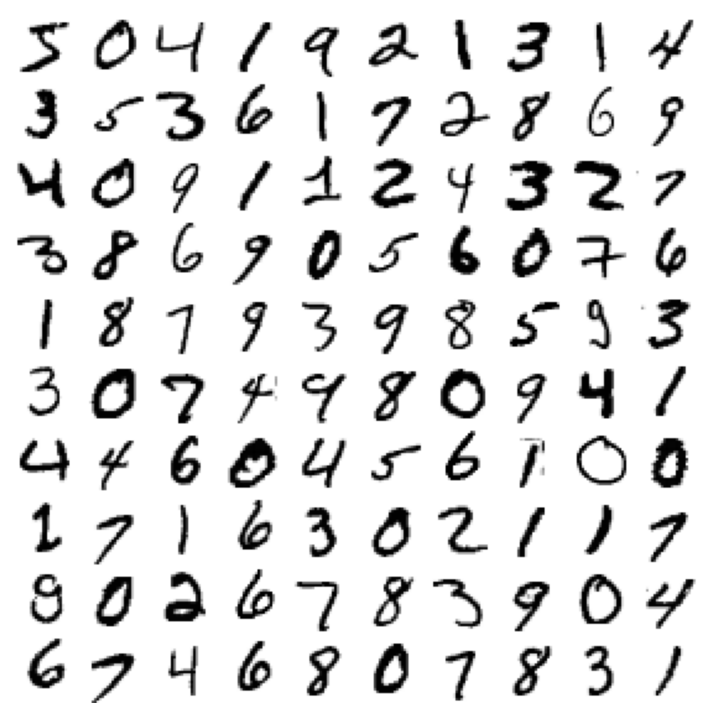

In [5]:
import matplotlib as mpl
import matplotlib.pyplot as plt

def plot_digit(data):
    image = data.reshape(28, 28)
    plt.imshow(image, cmap = mpl.cm.binary,
               interpolation="nearest")
    plt.axis("off")

def plot_digits(instances, images_per_row=10, **options):
    size = 28
    images_per_row = min(len(instances), images_per_row)

    n_rows = (len(instances) - 1) // images_per_row + 1
    # otra forma de indicar el número de filas seria:
    # n_rows = ceil(len(instances) / images_per_row)   *ceil* proporciona el número entero del cociente
    
    # Añadimos imagenes vacias para completar la cuadrícula
    n_empty = n_rows * images_per_row - len(instances)
    padded_instances = np.concatenate([instances, np.zeros((n_empty, size * size))], axis=0)

    # En el caso de encontra imágenes de diferente tamaño al establecido, esto orden las reajusta a ese tamaño
    image_grid = padded_instances.reshape((n_rows, images_per_row, size, size))

    # Se combinan los ejes 0 y 2 (verticales) con 1 y 3 (horizontales)
    # primero se colocan uno al lado del otro y se trasponen
    # reajustamos el tamaño de la imagen y obtenemos la caracterisitca de esa observaciñon
    big_image = image_grid.transpose(0, 2, 1, 3).reshape(n_rows * size,
                                                         images_per_row * size)
    
    # Tras realizar la transformación como deseamos de la imagen ya podemos mostrarla
    plt.imshow(big_image, cmap = mpl.cm.binary, **options)
    plt.axis("off")

plt.figure(figsize=(9,9))
example_images = X[:100] 


plot_digits(example_images, images_per_row=10) 
plt.show()


## Entrenament amb un classificador binari

En el primer exemple veurem cóm detectar el número 5 front a tots els demés. És a dir, serà positiu si és un 5 i negatiu si és un altre número.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fem una operació booleana amb el conjunt d'etiquetes per crear un conjunt de dades binari on només ens interessen els dígits 5.
y_train_5 = (y_train == 5)  # True for all 5s, False for all other digits
y_test_5 = (y_test == 5)    # True for all 5s, False for all other digits

Ens interessa explorar un classificador amb hiperparàmetres que siga ràpid i amb descens de gradient. Per simplicitat `SGDClassifier` és una bona opció. 

Els hiperparàmetres són:
* max_iter: El total màxim d'iteracions.
* tol: Criteri de parada, si arriba a aquest error es considera suficientment bó i para. 

> Tot i que internament està dissenyat a partir de classificadors lineals binaris, pot gestionar múltiples classes de manera automàtica. Estratègia One-vs-All (OvA): Per a un problema amb $K$ classes, l'algorisme entrena $K$ classificadors binaris diferents. Cadascun d'ells aprèn a distingir una de les classes de la resta de classes conjuntament. Predicció: Quan li passes una mostra, calcula la puntuació de confiança de cada classificador binari i tria la classe que obté la puntuació més alta.

In [7]:
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(max_iter=1000, tol=1e-3, random_state=42)
sgd_clf.fit(X_train, y_train_5)

,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only i

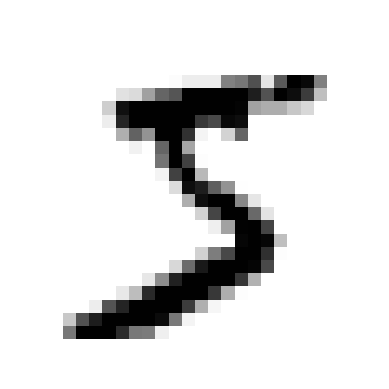

[False] 5


In [8]:


some_digit_image = X.iloc[0].to_numpy().reshape(28, 28) 
plt.imshow(some_digit_image, cmap=mpl.cm.binary) #indicamos que sea el color binary mpl.cm.gray
plt.axis("off")
plt.show()

print(sgd_clf.predict(X.iloc[[0]]), y.iloc[0])

### Mesures de rendiment

En els pasos anteriors hem fet un entrenament simple amb dades separades. Si volem saber si va a funcionar correctament amb totes les dades hem fer fer un Cross Validation. 

Finalment ja podriem entrenar amb totes les dades per posar el model en producció.

#### Cross-Validation

In [9]:
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

# 1. Creem un model NOU i no entrenat (buit) de SGDClassifier
sgd_clf_cv = SGDClassifier(max_iter=1000, tol=1e-3, random_state=42)

# 2. Definim l'estratègia
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 3. Li passem el model "buit" a la cross_val_score
y_train_5_cv = (y == 5)
scores = cross_val_score(sgd_clf_cv, X, y_train_5_cv, cv=skf, scoring='accuracy')

print("Puntuacions de cada plec:", scores)
print("Precisió mitjana:", scores.mean())

Puntuacions de cada plec: [0.96858661 0.93155617 0.94312776]
Precisió mitjana: 0.9477568452890498


#### Confusion Matrix

Obtenim la matriu de confusió. Com que estem provant en Cross Validation, cal treure les prediccions de totes les dades amb la mateixa metodologia:

In [12]:
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


sgd_clf_cm = SGDClassifier(max_iter=1000, tol=1e-3, random_state=42)

y_train_5_cm = (y == 5)

sgd_clf.fit(X_train, y_train_5)
y_train_pred = sgd_clf.predict(X_train)

# Calculem la matriu de confusió
conf_matrix = confusion_matrix(y_train_5, y_train_pred)


In [13]:
conf_matrix

array([[50630,   330],
       [ 1240,  3800]])

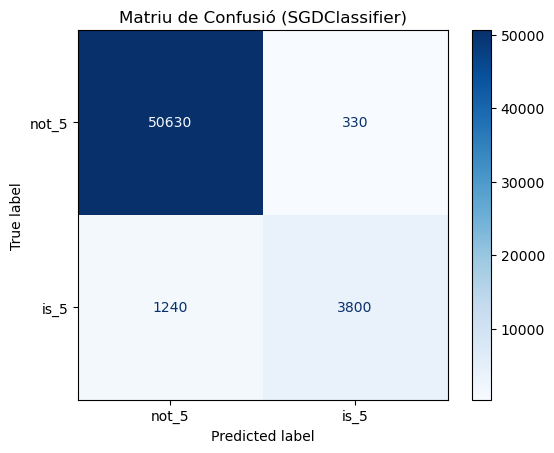

In [14]:

# 6. Visualitzem la matriu gràficament
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=["not_5", "is_5"]) # O simplement sense display_labels
disp.plot(cmap=plt.cm.Blues)
plt.title("Matriu de Confusió (SGDClassifier)")
plt.show()

Aquest classificador compara 5 front a totes les demés, està molt desequilibrat. Això farà que el model tinga un biaix cap a "no 5", ja que li donarà millors mètriques a l'entrenament. La solució pot ser fer `data augmentation` inventant nous 5s a partir dels 5 vertaders o eliminant del dataset una quantitat proporcional de la resta de números. 

També es pot afegir un hiperparàmetre més de `class weights` per penalitzar més quan s'equivoca en un 5 que quan s'equivoca en un "no 5". 

La matriu de confusió confirma que, proporcionalment, dona més falsos negatius que falsos positius. 

#### Precision / Recall

In [16]:
from sklearn.metrics import precision_score, recall_score

print("Precision:", precision_score(y_train_5, y_train_pred))
print("Recall:", recall_score(y_train_5, y_train_pred))

Precision: 0.9200968523002422
Recall: 0.753968253968254


#### Compensació entre Precision/Recall

Amb `decision_function` obtenim les puntuacions entre un parell de classes. La **`decision_function`** és un mètode que tenen molts classificadors de scikit-learn (com `SGDClassifier`, `LogisticRegression` o `SVC`) que et retorna **la puntuació de confiança (o marge)** de cada mostra respecte a les classes, en lloc de donar-te directament la classe predita (com fa `.predict()`).

Si és negatiu prediu 0, és a dir, que no és 5 i si és positiu prediu 1, és a dir, 5.

Per tant, si coneguem quant de segur està un model d'un número, podem exigir més seguretat o menys per a la predicció. A més seguretat, augmentarà la precisió. Per tant, no fallarà tant en les respostes positives. No obstant es deixarà moltes positives per detectar. Si deixem més laxitud a l'hora de detectar els positius, tindrem menys precisió i més `recall` o memòria. 



In [14]:
mnist.frame[mnist.frame['class'] == "5"].head(5)

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784,class
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
11,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
35,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
47,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
65,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5


In [15]:
y_scores = sgd_clf.decision_function(X[mnist.frame['class'] == "5"].head(5))  # Com que X no té les etiquetes, només passem les imatges de la classe 5 per obtenir els scores de decisió
y_scores

array([-372.88017823, 1850.88811131,  711.7565112 , 5704.75748092,
       7238.12977916])

In [16]:
threshold = 0
y_some_digit_pred = (y_scores > threshold)
y_some_digit_pred

array([False,  True,  True,  True,  True])

In [17]:
threshold = 8000
y_some_digit_pred = (y_scores > threshold)
y_some_digit_pred

array([False, False, False, False, False])

Canviant el `threshold` a 8000 es veu com té més falsos negatius, per exemple. 

In [17]:
from sklearn.model_selection import cross_val_predict

y_train_5_cm = (y == 5)
y_scores = cross_val_predict(sgd_clf_cm, X, y_train_5_cm, cv=3, method="decision_function")

Al `cross_val_predict` hem afegir el `method="decision_function"`. Aquest mètode entrena 3 models amb diferents particions i treu la mitjana. El resultat no és si és 5 o no és 5, sino el resultat de la funció a falta d'aplicar el `threshold`.

In [18]:
y_scores[:5]

array([   615.41107459, -17533.31133424, -24984.13602418,  -9555.91051244,
       -14342.7546473 ])

La funció `precision_recall_curve` ens dona un dataset per dibuixar una gràfica d'aquesta corva. 

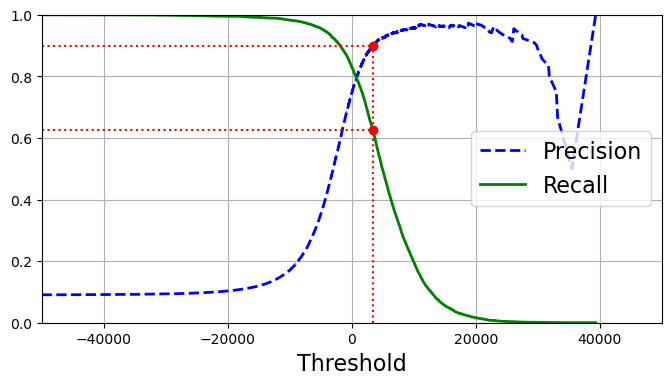

In [19]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_train_5_cm, y_scores)

def plot_precision_recall_vs_threshold(precisions, recalls, thresholds):
    plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2) #b- tipo de linea
    plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2) #g-- tipo del linea
    plt.legend(loc="center right", fontsize=16) 
    plt.xlabel("Threshold", fontsize=16)        
    plt.grid(True)                              
    plt.axis([-50000, 50000, 0, 1])             



recall_90_precision = recalls[np.argmax(precisions >= 0.90)]
threshold_90_precision = thresholds[np.argmax(precisions >= 0.90)]


plt.figure(figsize=(8, 4))                                                                  
plot_precision_recall_vs_threshold(precisions, recalls, thresholds)
plt.plot([threshold_90_precision, threshold_90_precision], [0., 0.9], "r:")                 
plt.plot([-50000, threshold_90_precision], [0.9, 0.9], "r:")                                
plt.plot([-50000, threshold_90_precision], [recall_90_precision, recall_90_precision], "r:")
plt.plot([threshold_90_precision], [0.9], "ro")                                             
plt.plot([threshold_90_precision], [recall_90_precision], "ro")                                                                          
plt.show()

Si volem evitar els falsos negatius, necessitem un recall alt (idealment 1).

El preu a pagar és que acceptarem molts falsos positius (la precisió baixarà).

> Tot depèn del cas d'ús: no tenir falsos negatius és crític en medicina (per exemple, no detectar un tumor), on prefereixes espantar el pacient amb un fals positiu que deixar escapar un malalt real. En canvi, en un filtre de correu borrissol (spam), potser prefereixes no tenir falsos positius (que un correu important vagi a spam).


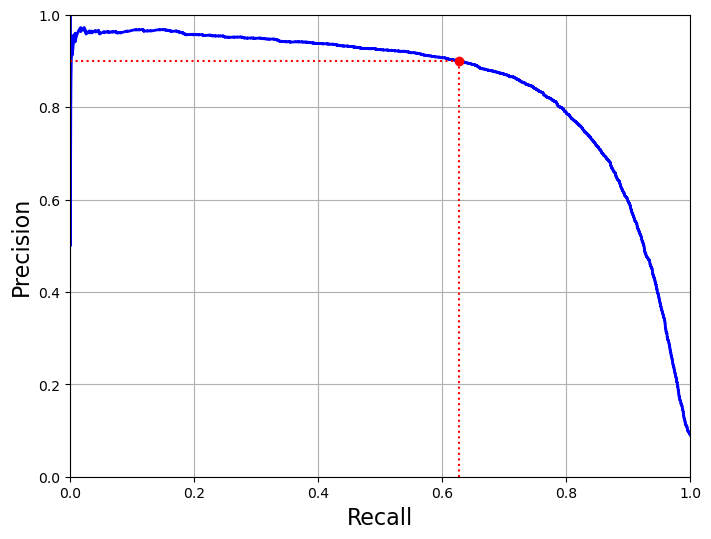

In [20]:
def plot_precision_vs_recall(precisions, recalls):
    plt.plot(recalls, precisions, "b-", linewidth=2)
    plt.xlabel("Recall", fontsize=16)
    plt.ylabel("Precision", fontsize=16)
    plt.axis([0, 1, 0, 1])
    plt.grid(True)

plt.figure(figsize=(8, 6))
plot_precision_vs_recall(precisions, recalls)
plt.plot([recall_90_precision, recall_90_precision], [0., 0.9], "r:")
plt.plot([0.0, recall_90_precision], [0.9, 0.9], "r:")
plt.plot([recall_90_precision], [0.9], "ro")

plt.show()

Al fer `precision_recall_curve` obtenim uns arrays que serveixen per a fer el gràfic, però també per pendre decisions. En la gràfica anterior i la de dalt, hem buscat el lloc on la precisió és 90. S'ha fet amb `argmax`, que és una funció molt útil del `Numpy` que ens indica la posició del primer True que troba a l'array (1). Com que l'array començarà amb poca precisió, els primers elements són False. El màxim és 1 (True) i per tant troba el primer True. 

In [21]:
print(precisions)
print("Recall at 90% precision:", recall_90_precision)
print('Llindar a 90% de precisió: ',threshold_90_precision)

[0.09018571 0.090187   0.09018829 ... 0.5        1.         1.        ]
Recall at 90% precision: 0.6261682242990654
Llindar a 90% de precisió:  3349.1918425320832


Si utilitzem el criteri del 90% tindrem un 90% de precisió i menys recall:

In [22]:
y_train_pred_90 = (y_scores >= threshold_90_precision)
precision_90 = precision_score(y_train_5_cm, y_train_pred_90)
recall_90 = recall_score(y_train_5_cm, y_train_pred_90)
print('El valor de la precisió és: ',precision_90)
print('El valor de la memòria és: ',recall_90)

El valor de la precisió és:  0.9000455373406193
El valor de la memòria és:  0.6261682242990654


#### Curva ROC

La curva ROC representa la tasa positiva verdadera (Recall) en comparació amb la tasa positiva falsa. És una representació de la sensibilitat o Recall. 

Igual que passava amb la corba de Precisió-Record, la corba ROC avalua el comportament del model a tots els llindars possibles.

* Un model perfecte tindria una corba que puja directe amunt fins a l'esquina superior esquerra (moltíssims positius veritables amb un 0% de falsos positius).
* Un model totalment aleatori seria una línia diagonal recta de punta a punta.
* Un model que estiga per sota de la línia diagonal (on l'AUC seria inferior a 0.5) és pitjor que triar a l'atzar.

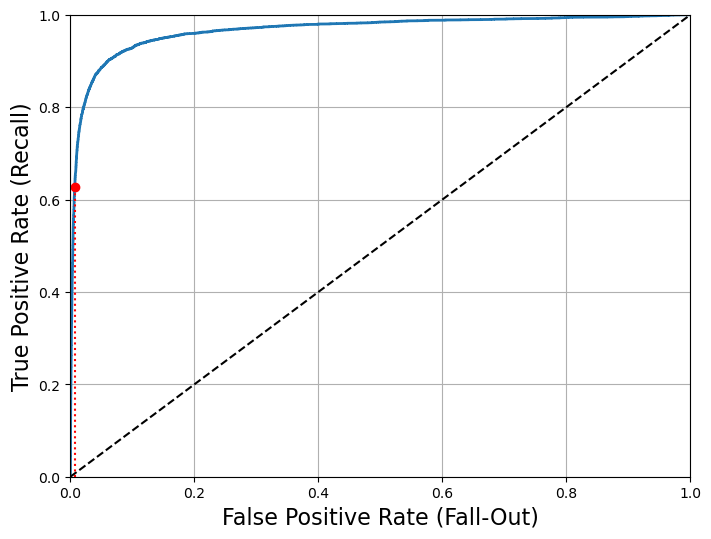

In [23]:
from sklearn.metrics import roc_curve

# roc_curve retorna tres arrays: fpr (false positive rate), tpr (true positive rate) i thresholds (llindars corresponents)
fpr, tpr, thresholds = roc_curve(y_train_5_cm, y_scores)


def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label=label)
    plt.plot([0, 1], [0, 1], 'k--') 
    plt.axis([0, 1, 0, 1])                                    
    plt.xlabel('False Positive Rate (Fall-Out)', fontsize=16) 
    plt.ylabel('True Positive Rate (Recall)', fontsize=16)    
    plt.grid(True)                                            

plt.figure(figsize=(8, 6))                                    
plot_roc_curve(fpr, tpr)
fpr_90 = fpr[np.argmax(tpr >= recall_90_precision)]           
plt.plot([fpr_90, fpr_90], [0., recall_90_precision], "r:")   
plt.plot([0.0, fpr_90], [recall_90_precision, recall_90_precision], "r:")  
plt.plot([fpr_90], [recall_90_precision], "ro")              
                                   
plt.show()

La corva indica que, a mesura que millorem el recall també augmenta la ratio de falsos positius. 

Si no necessitem la gràfica, l'àrea baix la corva ROC ens dona la mateixa informació:

In [24]:
from sklearn.metrics import roc_auc_score

score_auc = roc_auc_score(y_train_5_cm, y_scores)
print('La puntuació AUC és: ',score_auc)

La puntuació AUC és:  0.966907458229373


Ja que estem, anem a comparar la corva ROC amb un altre:

In [26]:
from sklearn.ensemble import RandomForestClassifier
forest_clf = RandomForestClassifier(n_estimators=100, random_state=42)
y_probas_forest = cross_val_predict(forest_clf, X, y_train_5_cm, cv=3,
                                    method="predict_proba")


In [27]:
y_probas_forest  # Primer element la probabilitat de no ser un 5 i el segon element la probabilitat de ser un 5

array([[0.11, 0.89],
       [0.98, 0.02],
       [1.  , 0.  ],
       ...,
       [0.98, 0.02],
       [0.14, 0.86],
       [0.98, 0.02]], shape=(70000, 2))

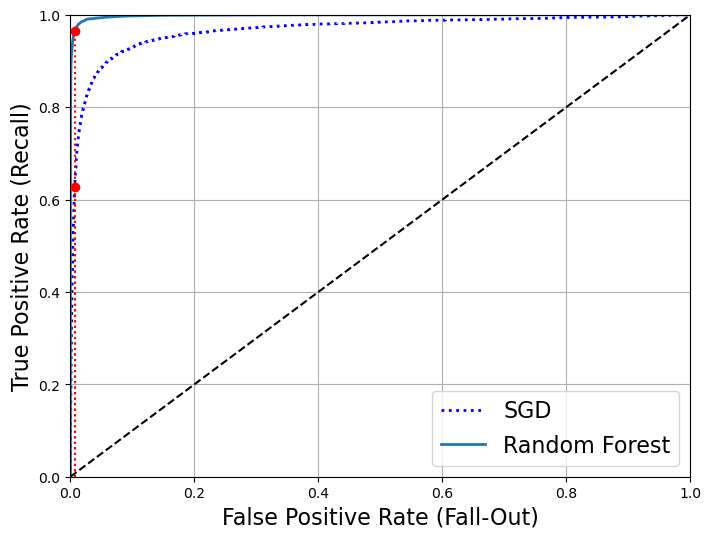

La puntuació AUC és:  0.966907458229373
La puntuació AUC del Random Forest és:  0.9984103571375105
Precisió (amb llindar 0.5): 0.9902
Record (amb llindar 0.5): 0.8772


In [28]:

y_scores_forest = y_probas_forest[:, 1] # score = probabilidad de la clase positiva
fpr_forest, tpr_forest, thresholds_forest = roc_curve(y_train_5_cm,y_scores_forest)

recall_for_forest = tpr_forest[np.argmax(fpr_forest >= fpr_90)]

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, "b:", linewidth=2, label="SGD")
plot_roc_curve(fpr_forest, tpr_forest, "Random Forest")
plt.plot([fpr_90, fpr_90], [0., recall_90_precision], "r:")
plt.plot([0.0, fpr_90], [recall_90_precision, recall_90_precision], "r:")
plt.plot([fpr_90], [recall_90_precision], "ro")
plt.plot([fpr_90, fpr_90], [0., recall_for_forest], "r:")
plt.plot([fpr_90], [recall_for_forest], "ro")
plt.grid(True)
plt.legend(loc="lower right", fontsize=16)

plt.show()

score_auc = roc_auc_score(y_train_5_cm, y_scores)
print('La puntuació AUC és: ',score_auc)

score_auc_forest = roc_auc_score(y_train_5_cm, y_scores_forest)
print('La puntuació AUC del Random Forest és: ',score_auc_forest)

threshold = 0.5

# Fem la predicció manual comparant amb el llindar
y_pred_custom = (y_scores_forest >= threshold)

#  Calculem la precisió i el record amb aquestes prediccions
precisio = precision_score(y_train_5_cm, y_pred_custom)
record = recall_score(y_train_5_cm, y_pred_custom)

print(f"Precisió (amb llindar {threshold}): {precisio:.4f}")
print(f"Record (amb llindar {threshold}): {record:.4f}")

Queda clar que en aquest cas un `Random Forest` ha funcionat millor que `SGDClassifier`, al menys en els hiperparàmetres que hem posat.

El SGDClassifier construeix un model lineal (un únic hiperplà per separar les dades). En canvi, el Random Forest combina centenars d'arbres de decisió, la qual cosa li permet aprendre regles no lineals molt més complexes i capturar millor els patrons visuals dels dígits (com les corbes del número 5).

> Com a exercici es podria entrenar i comparar amb un model de `LogisticRegression`. 

> Tal vegada has detectat que no hem normalitzat ni escalat les dades. de 0 a 255 pot fer que el model patisca amb dades extremes. Com a exercici escala les dades i prova si funciona correctament. 

## Entrenament amb classificadors multi classe

Els `Random Forest` i derivats o els `Naive Bayes` són molt adequats per a classificacions de moltes classes. Els altres classificadors poden funcionar bé sempre que s'aplique un algorismes `One-versus-all`. 

En aquest exemple compararem l'implementació i resultats de `SVC` i `XGBoost`. Però SVC és binari, per tant, aplicarà automàticament `One VS ALL`.

`SVC` no escala bé amb moltes dades i `XGBoost` comença a ser més eficient que `SVC` a partir de moltes dades. Tot està limitat a 1000 mostres per veure els resultats en minuts, però en aquest cas `SVC` podria no ser un bon model.  


In [24]:
X, y = mnist["data"], mnist["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Valor mínim:", np.min(X_train))
print("Valor màxim:", np.max(X_train))

from sklearn.preprocessing import StandardScaler, MinMaxScaler  
scaler = MinMaxScaler() # StandScaler() # MinMaxScaler() # Escalador de min a max (0 a 1) Funciona millor al ser blanc i negre. 
X_train_scaled = scaler.fit_transform(X_train.astype(np.float64))
print("Valor mínim (escalat):", np.min(X_train_scaled))
print("Valor màxim (escalat):", np.max(X_train_scaled))

Valor mínim: 0
Valor màxim: 255
Valor mínim (escalat): 0.0
Valor màxim (escalat): 1.0


In [25]:
print("Classes presents en  l'entrenament:", np.unique(y_train[:1000]))

Classes presents en  l'entrenament: [0 1 2 3 4 5 6 7 8 9]


In [26]:
from sklearn.svm import SVC

svm_clf = SVC(gamma="scale", random_state=42)
svm_clf.fit(X_train_scaled[:1000], y_train[:1000]) # y_train, no y_train_5


,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [27]:

# 1. Escalem les dades de predicció exactament igual que les dades d'entrenament
#X_test_scaled = X.iloc[:50] / 255.0
X_test_scaled = scaler.transform(X.iloc[:50].astype(np.float64))  # Escalem les dades de test amb el mateix scaler que vam utilitzar per a l'entrenament
# 2. Fem la predicció amb les dades escalades
print("Predicció: \n", svm_clf.predict(X_test_scaled))

# 3 Imprimeix els valors reals per comparar-ho
print("Valors reals: \n", y.iloc[:50].values)

Predicció: 
 [5 0 4 1 9 2 1 3 1 4 3 5 3 6 1 7 2 8 6 9 4 0 9 1 3 2 4 3 2 7 3 8 6 7 0 5 6
 0 7 6 1 8 7 9 3 9 8 5 5 3]
Valors reals: 
 [5 0 4 1 9 2 1 3 1 4 3 5 3 6 1 7 2 8 6 9 4 0 9 1 1 2 4 3 2 7 3 8 6 9 0 5 6
 0 7 6 1 8 7 9 3 9 8 5 9 3]


In [28]:
from sklearn.ensemble import HistGradientBoostingClassifier

xboost_clf = HistGradientBoostingClassifier(max_iter=100, random_state=42)
xboost_clf.fit(X_train_scaled[:1000], y_train[:1000]) # y_train, no y_train_5

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing val

In [29]:
print("Predicció: \n", xboost_clf.predict(X_test_scaled))

print("Valors reals: \n", y.iloc[:50].values)

Predicció: 
 [5 0 3 1 9 2 1 3 1 4 3 5 3 6 1 7 2 8 6 9 4 0 9 1 5 2 4 3 2 7 3 8 6 9 0 5 6
 0 7 6 1 8 7 9 3 9 8 5 3 3]
Valors reals: 
 [5 0 4 1 9 2 1 3 1 4 3 5 3 6 1 7 2 8 6 9 4 0 9 1 1 2 4 3 2 7 3 8 6 9 0 5 6
 0 7 6 1 8 7 9 3 9 8 5 9 3]


### Mètriques dels dos models



In [30]:
y_train_pred = cross_val_predict(svm_clf, X_train_scaled[:1000], y_train[:1000], cv=3)
conf_mx = confusion_matrix(y_train[:1000], y_train_pred)
conf_mx

array([[109,   0,   1,   0,   0,   1,   1,   0,   0,   0],
       [  0, 103,   1,   0,   0,   0,   0,   0,   0,   0],
       [  2,   1,  86,   1,   1,   0,   2,   1,   1,   1],
       [  1,   1,   1,  95,   0,   4,   1,   1,   4,   1],
       [  0,   0,   0,   0,  67,   0,   0,   0,   1,   5],
       [  0,   0,   0,   5,   2,  92,   1,   0,   0,   1],
       [  1,   1,   1,   0,   0,   2,  99,   0,   0,   0],
       [  1,   1,   0,   1,   1,   0,   0, 104,   0,   2],
       [  1,   3,   2,   4,   1,   3,   1,   0,  71,   4],
       [  0,   0,   0,   2,   3,   0,   0,   4,   0,  92]])

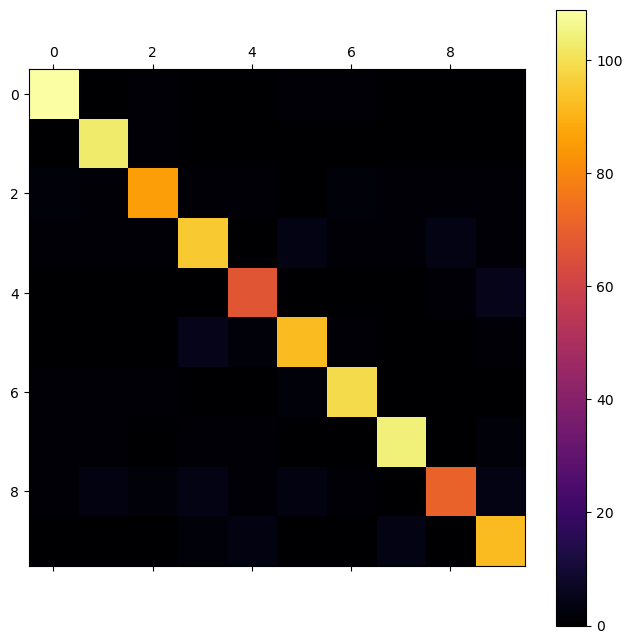

In [32]:
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111)
cax = ax.matshow(conf_mx, cmap="inferno")
fig.colorbar(cax)


Si només mirem els errors en nombres absoluts (per exemple, "el model s'ha equivocat 50 vegades amb el número 5"), et pots portar a engany:

* Potser el número 5 apareix 10.000 vegades al dataset de test (per tant, 50 errors és un percentatge mínim).
* En canvi, potser el número 5 apareix només 100 vegades (per tant, 50 errors significa que el model falla la meitat de les vegades).

Dividint cada fila de la matriu pel total d'elements de cada classe, convertim els nombres absoluts en proporcions o percentatges d'error, la qual cosa ens permet comparar classes que tenen un nombre molt diferent de mostres. 

Posant `normalize='true'` fa la divisió.

També podem omplir la diagonal de 0 per a que destaquen els errors

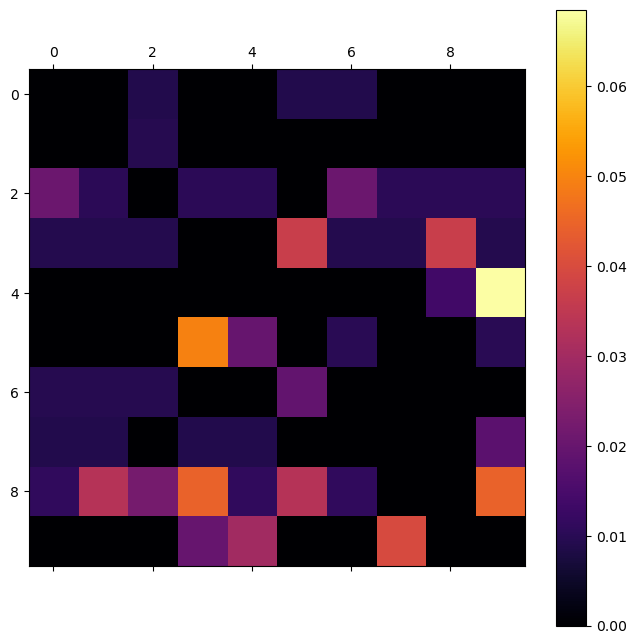

In [34]:
conf_mx_norm = confusion_matrix(y_train[:1000], y_train_pred[:1000], normalize='true')

np.fill_diagonal(conf_mx_norm, 0)

fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111)
cax = ax.matshow(conf_mx_norm, cmap="inferno")
fig.colorbar(cax)

Es pot veure que la columna 8 té en general més errors que altres, això vol dir que altres números es classifiquen com 8. La fila també està més brillant, això són 8s que es confonen amb altres números. La confusió entre el 3 i el 5 i el 8 es veu ací clarament també. 

Mirem el dataset on encerta i on falla:

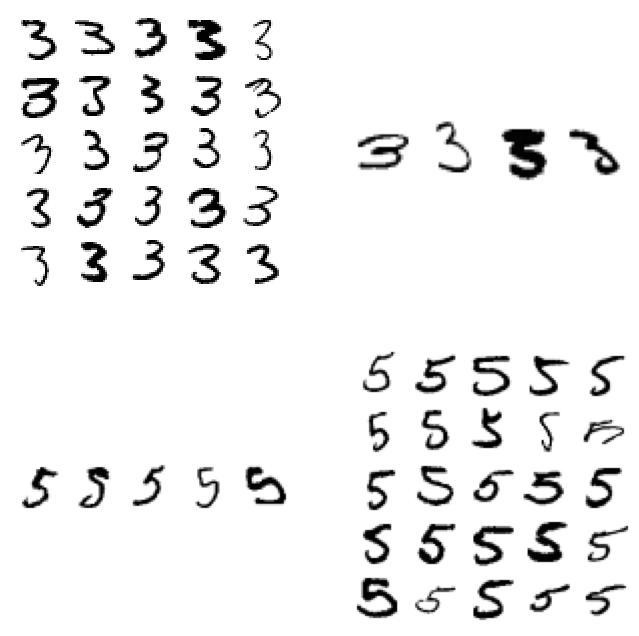

In [35]:
def plot_3_5(X_train, y_train, y_train_pred):
    cl_a, cl_b = 3, 5
    X_aa = X_train[(y_train == cl_a) & (y_train_pred == cl_a)]
    X_ab = X_train[(y_train == cl_a) & (y_train_pred == cl_b)]
    X_ba = X_train[(y_train == cl_b) & (y_train_pred == cl_a)]
    X_bb = X_train[(y_train == cl_b) & (y_train_pred == cl_b)]

    plt.figure(figsize=(8,8))
    plt.subplot(221); plot_digits(X_aa[:25], images_per_row=5)
    plt.subplot(222); plot_digits(X_ab[:25], images_per_row=5)
    plt.subplot(223); plot_digits(X_ba[:25], images_per_row=5)
    plt.subplot(224); plot_digits(X_bb[:25], images_per_row=5)

    plt.show()

plot_3_5(X_train[:1000], y_train[:1000], y_train_pred[:1000])

Generem els mateixos gràfics per al XGBoost:

In [36]:
y_train_pred_xg = cross_val_predict(xboost_clf, X_train_scaled[:1000], y_train[:1000], cv=3)


In [37]:
conf_mx_xg = confusion_matrix(y_train[:1000], y_train_pred_xg)
conf_mx_xg

array([[107,   0,   2,   2,   0,   0,   1,   0,   0,   0],
       [  0, 100,   2,   0,   0,   0,   0,   1,   1,   0],
       [  2,   1,  81,   1,   1,   0,   4,   0,   5,   1],
       [  1,   0,   7,  90,   1,   4,   0,   1,   4,   1],
       [  1,   0,   1,   1,  59,   1,   0,   0,   1,   9],
       [  2,   0,   2,   6,   1,  85,   2,   2,   0,   1],
       [  2,   0,   0,   0,   1,   2,  97,   0,   2,   0],
       [  0,   1,   2,   0,   2,   1,   0, 101,   0,   3],
       [  0,   5,   0,   5,   0,   4,   1,   1,  65,   9],
       [  0,   0,   1,   1,   1,   1,   0,   3,   3,  91]])

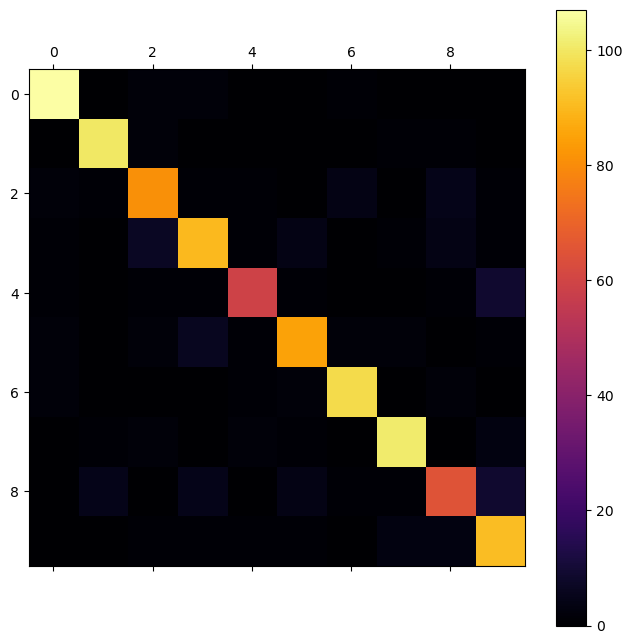

In [40]:
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111)
cax = ax.matshow(conf_mx_xg, cmap="inferno")
fig.colorbar(cax)

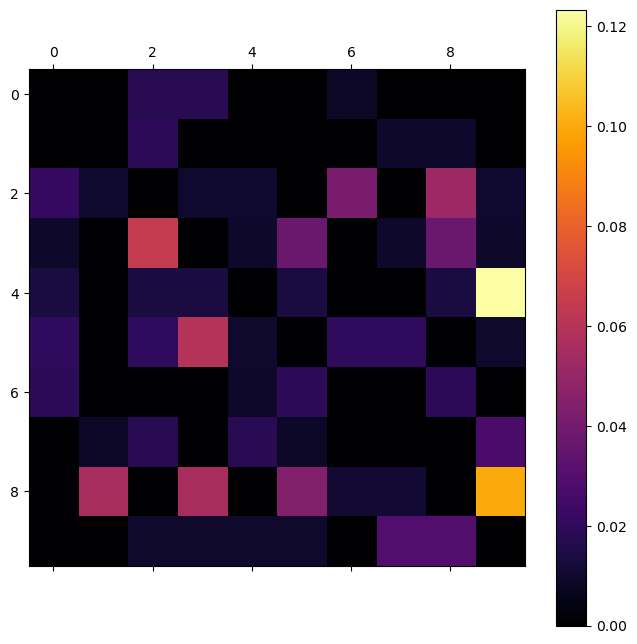

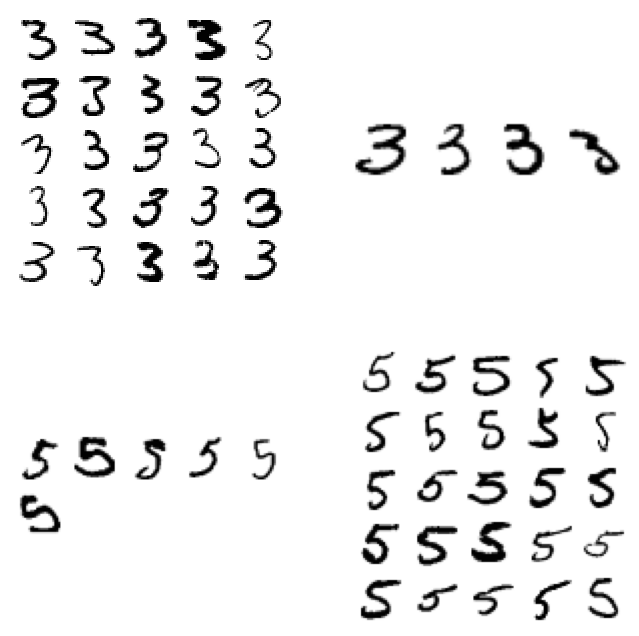

In [41]:
conf_mx_norm_xg = confusion_matrix(y_train[:1000], y_train_pred_xg, normalize='true')

np.fill_diagonal(conf_mx_norm_xg, 0)

fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111)
cax = ax.matshow(conf_mx_norm_xg, cmap="inferno")
fig.colorbar(cax)

plot_3_5(X_train[:1000], y_train[:1000], y_train_pred_xg)

## Classificació Multi etiqueta

No és el mateix Multi classe que Multi Etiqueta. En el segon cas, el target són més d'una classe. 

Tant els argorismes d'arbres com els de veïns estan preparats nativament per a ser multilabel. Si ens interessa qualsevol altre es pot utilitzar `MultiOutputClassifier`

```python
multilabel_log_reg = MultiOutputClassifier(LogisticRegression())
```

Anem a crear un cas `multilabel` amb dos etiquetes sobre el dataset MNIST. En primer lloc anem a detectar si un número és imparell i en segon lloc si és major o igual a 7. En aquest cas utilitzarem, per variar, un classificador per veïns com `KNeighborsClassifier`:

In [42]:
from sklearn.neighbors import KNeighborsClassifier

y_train_large = (y_train >= 7)
y_train_odd = (y_train % 2 == 1)
y_multilabel = np.c_[y_train_large, y_train_odd] # .c_ és una forma de concatenar arrays columna a columna.  

print("Classes presents en l'entrenament multilabel:", np.unique(y_multilabel, axis=0))


Classes presents en l'entrenament multilabel: [[False False]
 [False  True]
 [ True False]
 [ True  True]]


In [43]:

knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train[:1000], y_multilabel[:1000])  # Entrenem només amb les primeres 1000 mostres per agilitzar el procés

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier",list,"[array([False, True]), array([False, True])]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [44]:
#knn_clf.predict(X.iloc[[0]])

print("Predicció multilabel per a la primera imatge:", knn_clf.predict(X.iloc[[0]]), "Valors reals:", y.iloc[0], "y_multilabel real:", y_multilabel[0])

Predicció multilabel per a la primera imatge: [[False  True]] Valors reals: 5 y_multilabel real: [False  True]


El següent codi tarda molt. Dona un bon resultat major a 0.95.

> El K-Nearest Neighbors (KNN) es comporta com un algorisme de tipus «mandrós» (*lazy learner*) que no realitza cap procés d'optimització durant l'entrenament (`.fit()`), sinó que es limita a emmagatzemar tot el conjunt de dades. Consegüentment, tot el pes computacional recau en la fase de predicció, on el model ha de calcular de manera exhaustiva la distància matemàtica entre cada nova mostra i la totalitat de les dades d'entrenament. En aplicar una validació creuada (`cross_val_predict`), aquest costós procés de càlcul de distàncies es multiplica a través de les diferents particions i combinacions, la qual cosa explica per què el temps d'execució s'incrementa de forma molt superior a una simple relació lineal en comparació amb un entrenament convencional.

In [48]:
from sklearn.model_selection import cross_val_predict

y_train_knn_pred = cross_val_predict(knn_clf, X_train[:1000], y_multilabel[:1000], cv=3)
f1_score(y_multilabel[:1000], y_train_knn_pred, average="macro")

0.9128366724556723

In [50]:
from sklearn.metrics import multilabel_confusion_matrix

# Calcula una matriu 2x2 per a cada etiqueta
mcm = multilabel_confusion_matrix(y_multilabel[:1000], y_train_knn_pred)

print("Matriu de confusió per a la primera etiqueta:\n", mcm[0])
print("\nMatriu de confusió per a la segona etiqueta:\n", mcm[1])

Matriu de confusió per a la primera etiqueta:
 [[665  34]
 [ 30 271]]

Matriu de confusió per a la segona etiqueta:
 [[409  66]
 [ 10 515]]


In [51]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Convertim les dues columnes binàries en una sola classe entera (ex: codificació binària a decimal)
# Suposant que y_multilabel i y_train_knn_pred tenen forma (n_mostres, 2)
y_true_combined = y_multilabel[:1000, 0] * 2 + y_multilabel[:1000, 1]
y_pred_combined = y_train_knn_pred[:1000, 0] * 2 + y_train_knn_pred[:1000, 1]

# Ara fem la matriu de confusió de tota la vida (de 4x4)
conf_matrix_combined = confusion_matrix(y_true_combined, y_pred_combined)
print(conf_matrix_combined)

[[340  19   1  25]
 [  3 303   2   6]
 [  4  18  64   4]
 [  4   4   1 202]]


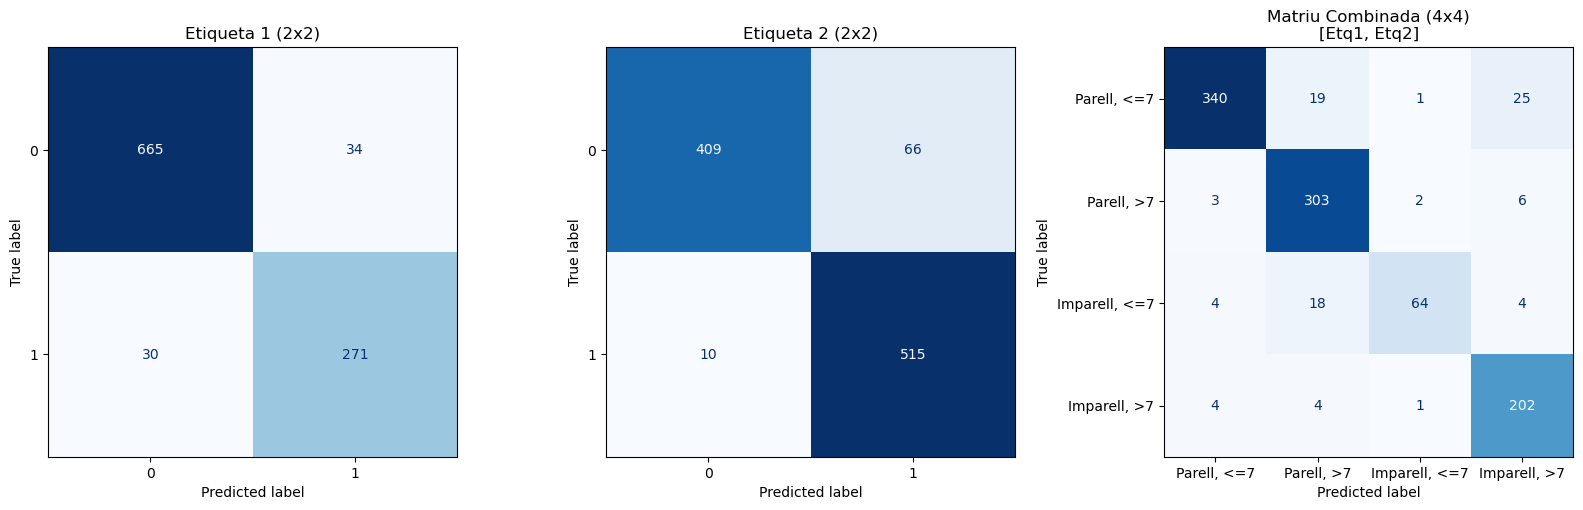

In [53]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import multilabel_confusion_matrix, confusion_matrix, ConfusionMatrixDisplay

# 1. Calculem les matrius individuals (2x2)
mcm = multilabel_confusion_matrix(y_multilabel[:1000], y_train_knn_pred)

# 2. Calculem la matriu combinada (4x4)
y_true_combined = y_multilabel[:1000, 0] * 2 + y_multilabel[:1000, 1]
y_pred_combined = y_train_knn_pred[:1000, 0] * 2 + y_train_knn_pred[:1000, 1]
conf_matrix_combined = confusion_matrix(y_true_combined, y_pred_combined)

# 3. Creem una figura amb 3 subplots (1 fila, 3 columnes)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Matriu Etiqueta 1
disp_0 = ConfusionMatrixDisplay(confusion_matrix=mcm[0])
disp_0.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Etiqueta 1 (2x2)")

# Matriu Etiqueta 2
disp_1 = ConfusionMatrixDisplay(confusion_matrix=mcm[1])
disp_1.plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Etiqueta 2 (2x2)")

# Matriu Combinada (4x4)
disp_comb = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_combined, 
    display_labels = [
    "Parell, <=7",  # [0, 0] -> No imparell, No major que 7
    "Parell, >7",   # [0, 1] -> No imparell, Sí major que 7 (el 8)
    "Imparell, <=7", # [1, 0] -> Sí imparell, No major que 7
    "Imparell, >7"   # [1, 1] -> Sí imparell, Sí major que 7 (el 9)
]
)
disp_comb.plot(ax=axes[2], cmap="Blues", colorbar=False)
axes[2].set_title("Matriu Combinada (4x4)\n[Etq1, Etq2]")

# Ajustem l'espai i mostrem el resultat
plt.tight_layout()
plt.show()

## Classificador MultiEixida

Multilabel és un cas particula de multieixida en el que totes les classes són binàries. Si volem tenim moltes eixides en les que puguen ser binàries, multiclasse o inclús regressió, estem parlant d'un model multieixida. 

L'eixida de la `y` serà una matriu o cada columna és d'un tipus. 

Segurament acabaríem utilitzant una xarxa neuronal amb varies eixides i varies capes, però com estem encara en `machine learning tradicional`, els algorismes que poden inferir varies eixides són els `Random Forest` on la Y pot ser un "pack" i els `KNN` on calcular eixes característiques diverses per votació o mitjana dels veïns.

Scikit-Learn inclou eines anomenades metagestors que s'encarreguen d'adaptar qualsevol model `MultiOutputClassifier` i `MultiOutputRegressor` per utilitzar internament altres algorismes. 

En el context de la neteja d'imatges (*image denoising*), ens trobem davant d'un exemple paradigmàtic de **predicció multieixida (*multi-output*)**. A diferència d'un problema de classificació tradicional on el model emet una única sortida global, en aquest cas la variable objectiu ($y$) està composta per un vector de **784 dimensions** (equivalent al nombre total de píxels de la imatge $28 \times 28$).

El model no es limita a predir un estat binari per etiqueta, sinó que actua com un conjunt massiu d'estimadors simultanis on **cada píxel individual funciona com un eix de predicció independent** capaç d'adoptar un rang multinivell d'intensitat lumínica. Per tant, l'algorisme ha de mapejar una entrada trigada de soroll cap a un vector de sortida d'alta dimensionalitat, convertint-se en una extensió natural de la multieixida aplicada a la reconstrucció de dades contínues o discretes.


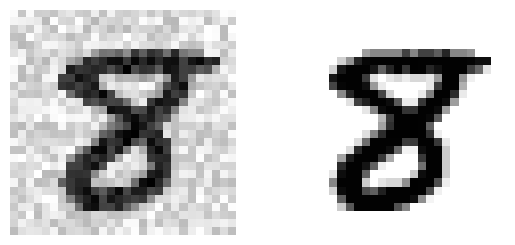

In [54]:
import numpy as np


X_train = X_train.to_numpy()
X_test = X_test.to_numpy()


noise = np.random.randint(0, 100, (len(X_train), 784))
X_train_mod = X_train + noise
noise = np.random.randint(0, 100, (len(X_test), 784))
X_test_mod = X_test + noise
y_train_mod = X_train
y_test_mod = X_test

some_index = 0
plt.subplot(121); plot_digit(X_test_mod[some_index])
plt.subplot(122); plot_digit(y_test_mod[some_index])
plt.show()

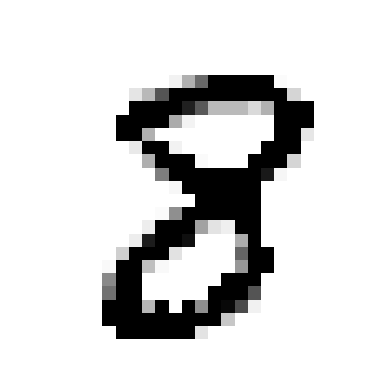

In [55]:
knn_clf.fit(X_train_mod, y_train_mod)
clean_digit = knn_clf.predict([X_test_mod[some_index]])
plot_digit(clean_digit)


Si l'únic objectiu és netejar el soroll d'una imatge de manera clàssica (sense utilitzar xarxes neuronals), els algorismes de Machine Learning per a regressió no solen ser el millor mètode.

Per a netejar imatges de manera no neuronal, s'utilitzen filtres algorítmics tradicionals (de la llibreria scikit-image o scipy), com ara:
* Filtre de Mediana (Median Filter): Excel·lent per eliminar soroll de tipus "sal i pimbre" (píxels blancs o negres aleatoris aïllats).
* Filtre de Wiener o Non-Local Means: Algorismes matemàtics de tractament d'imatge que netegen el fons respectant les vores i les línies del número.

Aquests filtres tradicionals són instantanis, no requereixen hores d'entrenament prèvia i sovint deixen la imatge molt més neta per a un humà (o per a un classificador) que qualsevol Random Forest fent regressió de 784 sortides.

## Altres classificacions

### Classificador Dummie

És útil com a referència d'un classificador que no te en compte les variables d'entrada i per tant té un comportament aleatori. 

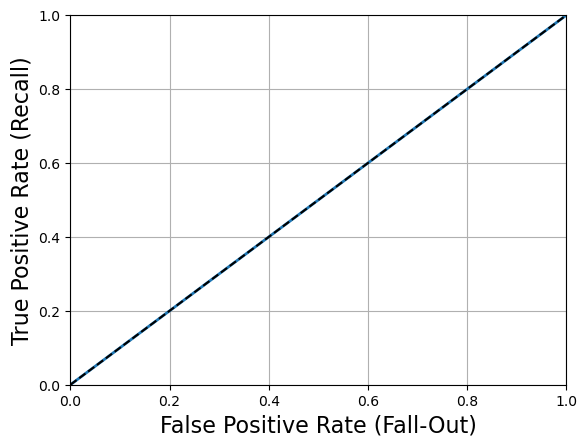

In [24]:
from sklearn.dummy import DummyClassifier

def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label=label)
    plt.plot([0, 1], [0, 1], 'k--') 
    plt.axis([0, 1, 0, 1])                                    
    plt.xlabel('False Positive Rate (Fall-Out)', fontsize=16) 
    plt.ylabel('True Positive Rate (Recall)', fontsize=16)    
    plt.grid(True)  

dmy_clf = DummyClassifier(strategy="prior")
y_probas_dmy = cross_val_predict(dmy_clf, X_train, y_train_5, cv=3, method="predict_proba")
y_scores_dmy = y_probas_dmy[:, 1]
fprr, tprr, thresholdsr = roc_curve(y_train_5, y_scores_dmy)
plot_roc_curve(fprr, tprr)

### Augmentació de dades

El següent exemple serveix per a fer augmentació de dades (data augmentation), una tècnica fonamental per a millorar la robustesa i la capacitat de generalització dels models de machine learning (i prové directament del famós llibre Hands-On Machine Learning de scikit-learn).

En entrenar un model (com un classificador lineal o un KNN) amb aquestes dades desplaçades, l'ensenyes a no dependre de si el número està perfectament centrat al mig de la imatge, reduint dràsticament l'error quan s'enfronti a dades reals on els dígits estiguin torçats o desplaçats.

In [26]:
from sklearn.neighbors import KNeighborsClassifier
knn_clf = KNeighborsClassifier(weights='distance', n_neighbors=4)
knn_clf.fit(X_train, y_train)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",4
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int8](10,)","[0,1,2,...,7,8,9]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [27]:

y_knn_pred = knn_clf.predict(X_test)
from sklearn.metrics import accuracy_score
accuracy_scr = accuracy_score(y_test, y_knn_pred)
print('Accuracy:', accuracy_scr)

Accuracy: 0.9731428571428572


/tmp/ipykernel_11739/1060322442.py:1: DeprecationWarning: Please import `shift` from the `scipy.ndimage` namespace; the `scipy.ndimage.interpolation` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.interpolation import shift


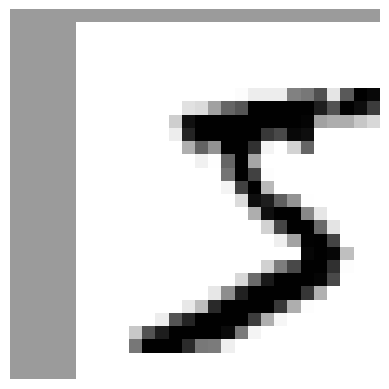

In [28]:
from scipy.ndimage.interpolation import shift
def shift_digit(digit_array, dx, dy, new=0):
    return shift(digit_array.reshape(28, 28), [dy, dx], cval=new).reshape(784)

plot_digit(shift_digit(X.iloc[0].to_numpy(), 5, 1, new=100))

In [30]:
X_train_expanded = [X_train]
y_train_expanded = [y_train]
for dx, dy in ((1, 0), (-1, 0), (0, 1), (0, -1)):
    shifted_images = np.apply_along_axis(shift_digit, axis=1, arr=X_train, dx=dx, dy=dy)
    X_train_expanded.append(shifted_images)
    y_train_expanded.append(y_train)

X_train_expanded = np.concatenate(X_train_expanded)
y_train_expanded = np.concatenate(y_train_expanded)
X_train_expanded.shape, y_train_expanded.shape

((280000, 784), (280000,))

In [31]:
knn_clf.fit(X_train_expanded, y_train_expanded)
y_knn_expanded_pred = knn_clf.predict(X_test)
accuracy_score(y_test, y_knn_expanded_pred)

0.9797142857142858

S'ha trobat un dígit ambigu a l'índex: 49
👉 Etiqueta REAL (y_test): 9
🤖 Predicció del model: 4 (Confiança: 50.1%)

Distribució de probabilitats per a cada número (del 0 al 9):
Dígit 0: 0.0%
Dígit 1: 0.0%
Dígit 2: 0.0%
Dígit 3: 0.0%
Dígit 4: 50.1%
Dígit 5: 0.0%
Dígit 6: 0.0%
Dígit 7: 0.0%
Dígit 8: 0.0%
Dígit 9: 49.9%


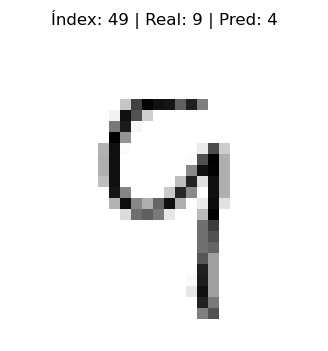

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Calculem les probabilitats per al rang del 0 al 1000
subset_probs = knn_clf.predict_proba(X_test[:1000])

# 2. Obtenim la probabilitat màxima (la confiança) per a cadascun d'aquests dígits
max_probs = np.max(subset_probs, axis=1)

# 3. Busquem un índex on la confiança sigui baixa (zona ambigua)
ambiguous_candidates = np.where((max_probs > 0.35) & (max_probs < 0.55))[0]

if len(ambiguous_candidates) > 0:
    ambiguous_index = ambiguous_candidates[0]
else:
    ambiguous_index = np.argmin(max_probs)

# 4. Obtenim l'etiqueta REAL de y_test per a aquest índex
real_label = y_test.iloc[ambiguous_index]
predicted_label = np.argmax(subset_probs[ambiguous_index])

# 5. Mostrem la informació per consola
print(f"S'ha trobat un dígit ambigu a l'índex: {ambiguous_index}")
print(f"👉 Etiqueta REAL (y_test): {real_label}")
print(f"🤖 Predicció del model: {predicted_label} (Confiança: {max_probs[ambiguous_index]*100:.1f}%)")
print("\nDistribució de probabilitats per a cada número (del 0 al 9):")
for digit, prob in enumerate(subset_probs[ambiguous_index]):
    print(f"Dígit {digit}: {prob*100:.1f}%")

# 6. Pintem la imatge amb els resultats al títol
plt.figure(figsize=(4, 4))
plot_digit(X_test[ambiguous_index])
plt.title(f"Índex: {ambiguous_index} | Real: {real_label} | Pred: {predicted_label}")
plt.show()

### Image-to-Image translation

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from sklearn.ensemble import ExtraTreesRegressor

# Assegura't de tenir X i y preparats (per exemple, els primers 1000 de MNIST)
n_samples = 1000
X_subset = X[:n_samples].to_numpy() if hasattr(X, 'to_numpy') else X[:n_samples]
y_subset = y[:n_samples].to_numpy() if hasattr(y, 'to_numpy') else y[:n_samples]

# 1. PAS 1: Crear X_train_mod (Imatges de MNIST amb soroll afegit)
np.random.seed(42)
noise = np.random.randint(0, 100, size=X_subset.shape)
X_train_mod = np.clip(X_subset + noise, 0, 255)

# 2. PAS 2: Funció per rasteritzar un número en una font neta (28x28)
def render_clean_digit(digit):
    # Creem una imatge negra de 28x28 (fons 0)
    img = Image.new('L', (28, 28), color=0)
    draw = ImageDraw.Draw(img)
    
    try:
        # Intentem carregar una font d'impremta estàndard
        font = ImageFont.truetype("DejaVuSans.ttf", 20)
    except IOError:
        # Si no la troba, utilitza la per defecte de PIL
        font = ImageFont.load_default()
    
    # Dibuixem el número centrat (blanc sobre negre)
    draw.text((8, 3), str(int(digit)), fill=255, font=font)
    
    # Convertim a array de NumPy i aplanem a 784 píxels
    return np.array(img, dtype=np.float32).flatten()

print("Generant el dataset de tipografia neta (Y)...")
# Construïm la matriu Y_train amb les imatges de font neta corresponents a y_subset
Y_train_font = np.array([render_clean_digit(label) for label in y_subset])

# 3. PAS 3: Entrenar el Random Forest Multieixida
print("Entrenant el ExtraTreesRegressor (això pot trigar un moment)...")
# Utilitzem n_estimators moderat per a 1000 mostres per no alentir-ho massa
rf_model = ExtraTreesRegressor(
    n_estimators=30, 
    random_state=42, 
    n_jobs=-1
)
rf_model.fit(X_train_mod, Y_train_font)
print("¡Entrenament finalitzat amb èxit!")


Generant el dataset de tipografia neta (Y)...
Entrenant el ExtraTreesRegressor (això pot trigar un moment)...
¡Entrenament finalitzat amb èxit!


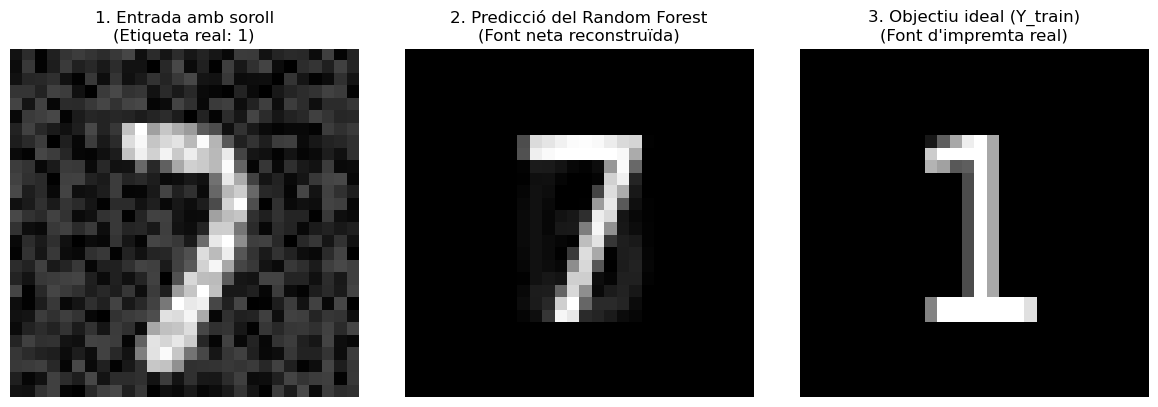

In [44]:

# 4. PAS D'INFERÈNCIA: Provem com funciona amb un element de prova
test_index = 3
pred_pixel_vector = rf_model.predict([X_test_mod[test_index]])[0]
# Redimensionem de nou a 28x28 per poder pintar-ho
predicted_image = pred_pixel_vector.reshape(28, 28)

# Visualització del resultat
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(X_test_mod[test_index].reshape(28, 28), cmap="gray")
plt.title(f"1. Entrada amb soroll\n(Etiqueta real: {y_subset[test_index]})")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(predicted_image, cmap="gray")
plt.title("2. Predicció del Random Forest\n(Font neta reconstruïda)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(Y_train_font[test_index].reshape(28, 28), cmap="gray")
plt.title("3. Objectiu ideal (Y_train)\n(Font d'impremta real)")
plt.axis("off")

plt.tight_layout()
plt.show()

En aquest bosc multieixida basat en trenta estimadors (*ExtraTreesRegressor*), el bosc no utilitza un arbre per cada píxel, sinó que **trenta arbres independents** processen simultàniament tot el vector d'entrada de 784 dimensions. Durant el procés, cadascun d'aquests arbres guia la informació a través de les seves branques fins a arribar a una fulla terminal que emet, de manera nativa, **un vector sencer de set-cents vuitanta-quatre valors continus** —que representa la mitjana de les imatges d'entrenament que van coincidir en aquesta partició—. Finalment, la predicció global s'obté calculant la **mitjana aritmètica dels trenta vectors obtinguts**, unificant el consens col·lectiu de tot el bosc per dibuixar la imatge reconstruïda final.

### Reducció de dimensionalitat



In [ ]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

# 1. Definim el PCA perquè retingui el 95% de la informació original
pca = PCA(n_components=0.95)

print("Reduint dimensions...")
X_train_reduced = pca.fit_transform(X_train)
X_test_reduced = pca.transform(X_test)

print(f"Dimensions originals: {X_train.shape[1]} píxels")
print(f"Dimensions reduïdes: {X_train_reduced.shape[1]} components principals")

# ESCALAT (Clau perquè lbfgs convergeixi ràpid)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_reduced)
X_test_scaled = scaler.transform(X_test_reduced)

# 2. Entrenem un classificador senzill i ràpid (Regressió Logística)
print("Entrenant el classificador...")
simple_clf = LogisticRegression(max_iter=1000, tol=1e-2, random_state=42) # He tingut que augmentar la tolerància perquè convergís més ràpidament i no dones errors de convergència. També he augmentat el nombre màxim d'iteracions a 1000.
simple_clf.fit(X_train_reduced, y_train)

# 3. Avaluem el resultat
y_pred = simple_clf.predict(X_test_reduced)
accuracy = accuracy_score(y_test, y_pred)

print(f"Precisió del model simple amb dades reduïdes: {accuracy * 100:.2f}%")

Reduint dimensions...
Dimensions originals: 784 píxels
Dimensions reduïdes: 154 components principals
Entrenant el classificador...
Precisió del model simple amb dades reduïdes: 91.49%


Tot i que el conjunt de dades MNIST compta amb set-cents vuitanta-quatre píxels inicials, l'Anàlisi de Components Principals (PCA) requereix al voltant de cent cinquanta dimensions per retenir la major part de la variança a causa de la forta correlació espacial i la continuïtat dels traços inherents a les imatges. En lloc de limitar-se a buscar les deu classes de dígits, el PCA opera identificant la variabilitat geomètrica i morfològica —com ara els diferents gruixos, inclinacions i estils d'escriptura de cada usuari—, necessitant aquest nombre de components per capturar tota la complexitat estructural del conjunt mentre descarta el soroll redundant i comprimeix eficientment l'espai de dades.

Per defecte, la LogisticRegression de scikit-learn no fa un One-vs-Rest (OvR) si utilitzes els optimitzadors moderns (com el solver lbfgs), sinó que aplica Regressió Logística Multinomial (també coneguda com a Softmax).

En lloc de separar el problema en 10 talls diferents, avalua totes les classes de cop de manera conjunta utilitzant una funció de pèrdua global (entropia creuada/softmax). Considerar les relacions mútues entre totes les classes alhora, acostuma a donar millors resultats i està molt ben calibrada.